# CodeAlpha Task 2 — Exploratory Data Analysis (EDA)

## Student Performance Dataset

### Objective

The objective of this project is to perform Exploratory Data Analysis (EDA) on a student performance dataset to understand the structure of the data, identify patterns and trends, detect anomalies, and investigate relationships between student characteristics and academic performance.

### Questions to Explore

1. What is the structure of the dataset and what types of variables are present?
2. How are the final grades (`G3`) distributed among students?
3. Is study time associated with students' final grades?
4. Is the number of absences associated with final grades?
5. Do previous academic failures relate to final performance?
6. Are there differences in final grades across different demographic groups?
7. Which variables have the strongest relationship with final grade?
8. Are there any unusual values or potential outliers in the dataset?
9. Are there statistically significant relationships between selected variables?

### EDA Process

The analysis will follow these stages:

1. Load the dataset
2. Understand the dataset structure
3. Check data types and missing values
4. Perform descriptive statistics
5. Analyze individual variables
6. Investigate relationships between variables
7. Detect outliers and anomalies
8. Visualize important patterns
9. Perform statistical hypothesis testing
10. Summarize findings and data quality issues

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the student performance dataset

df = pd.read_csv("../data/student_performance.csv")

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

Dataset loaded successfully!
Shape of dataset: (649, 33)


In [4]:
print(df.head())
print(df.tail())
print("Column Names:")
print(df.columns.tolist())


  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]
    school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
644     M

In [5]:
df.info()
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [6]:
missing_values = df.isnull().sum()
print(missing_values)
print("Total Missing Values:\n",missing_values.sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Total Missing Values:
 0


In [7]:
duplicated_count = df.duplicated().sum()
print(duplicated_count)

0


In [8]:
df.describe()


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [9]:
df.describe(include=object)

C:\Users\intel\AppData\Local\Temp\ipykernel_11224\3998025828.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=object)


,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
count,649,649,649,649,649,649,649,649,649,649,649,649,649,649,649,649,649
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,no,yes,yes,yes,no
freq,423,383,452,457,569,258,367,285,455,581,398,610,334,521,580,498,410


In [10]:
num_columns = df.select_dtypes(include=np.number).columns.tolist()
cat_columns = df.select_dtypes(include="object").columns.tolist()


print("Numerical Columns :\n", num_columns)
print("No. of Numerical Columns:\n", len(num_columns))

print("Categorical Columns :\n", cat_columns)
print("No. of Categorical Columns:\n", len(cat_columns))






Numerical Columns :
 ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
No. of Numerical Columns:
 16
Categorical Columns :
 ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
No. of Categorical Columns:
 17


C:\Users\intel\AppData\Local\Temp\ipykernel_11224\1902702296.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_columns = df.select_dtypes(include="object").columns.tolist()


In [11]:
print("Final Grade G3 Statistics:\n")
print("------------------------------")
print("Maximum:",df["G3"].max())
print("Minimum:",df["G3"].min())
print("Mean:",df["G3"].mean())
print("Median:",df["G3"].median())
print("Standard Deviation:",df["G3"].std())



Final Grade G3 Statistics:

------------------------------
Maximum: 19
Minimum: 0
Mean: 11.906009244992296
Median: 12.0
Standard Deviation: 3.230656242804805


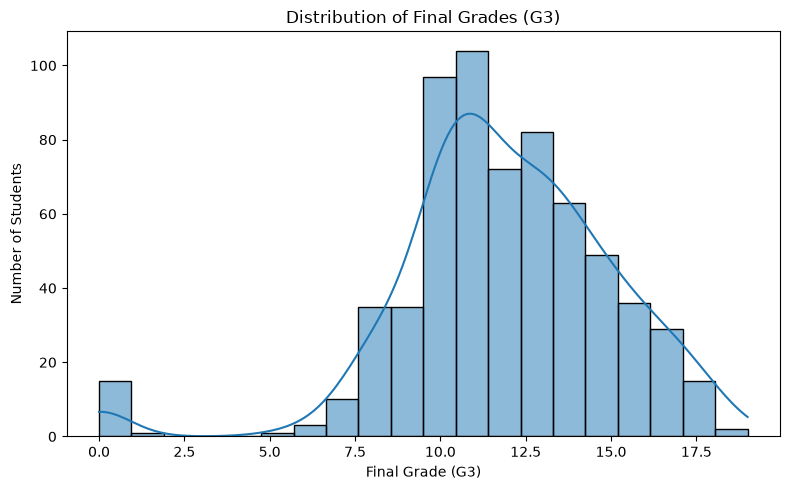

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=20, kde=True)

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("../screenshots/g3_distribution.png", dpi=300)
plt.show()


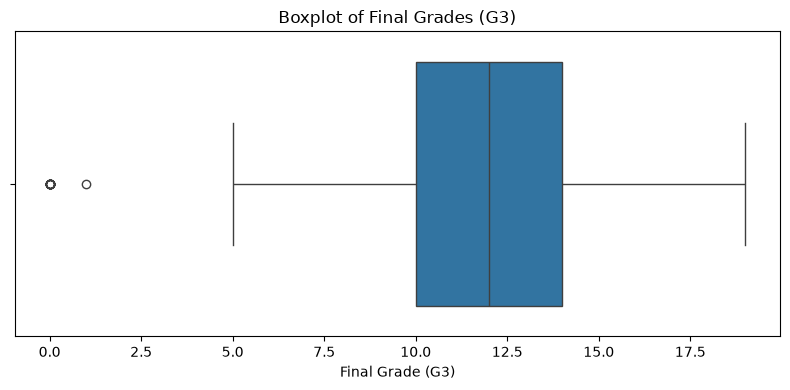

In [13]:
# Boxplot of final grades

plt.figure(figsize=(8, 4))

sns.boxplot(x=df["G3"])

plt.title("Boxplot of Final Grades (G3)")
plt.xlabel("Final Grade (G3)")

plt.tight_layout()
plt.savefig("../screenshots/g3_boxplot.png", dpi=300)
plt.show()

In [14]:
studytime_counts = df["studytime"].value_counts().sort_index()
print(studytime_counts)

studytime
1    212
2    305
3     97
4     35
Name: count, dtype: int64


In [15]:
# Average final grade by study-time category

studytime_g3 = df.groupby("studytime")["G3"].agg(
    ["count", "mean", "median", "std"]
)

print(studytime_g3)

           count       mean  median       std
studytime                                    
1            212  10.844340    11.0  3.218624
2            305  12.091803    12.0  3.243125
3             97  13.226804    13.0  2.502104
4             35  13.057143    13.0  3.038410


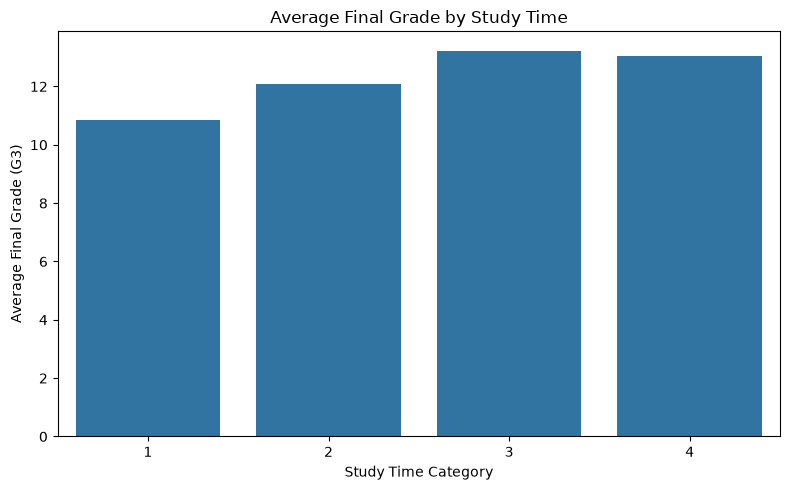

In [16]:
# Average final grade by study-time category

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="studytime",
    y="G3",
    errorbar=None
)

plt.title("Average Final Grade by Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade (G3)")

plt.tight_layout()
plt.savefig("../screenshots/studytime_vs_g3.png", dpi=300)
plt.show()

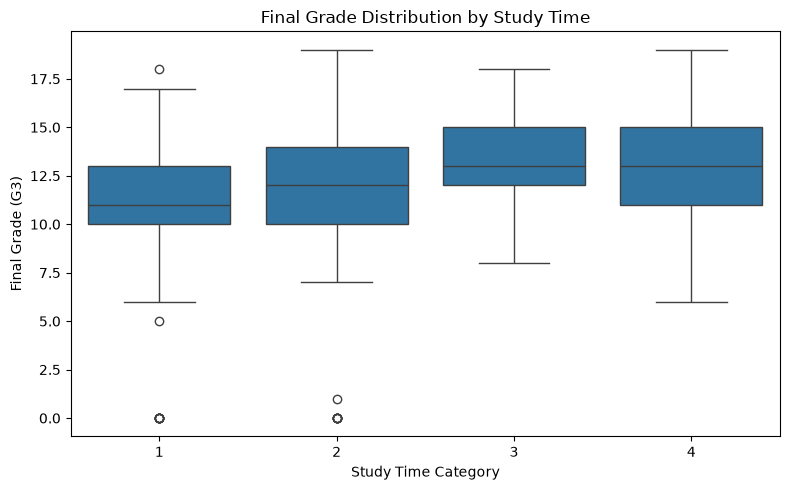

In [17]:
# Distribution of final grades across study-time categories

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="studytime",
    y="G3"
)

plt.title("Final Grade Distribution by Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade (G3)")

plt.tight_layout()
plt.savefig("../screenshots/studytime_g3_boxplot.png", dpi=300)
plt.show()

In [18]:
from scipy.stats import f_oneway

# Create G3 groups based on study time
group1 = df[df["studytime"] == 1]["G3"]
group2 = df[df["studytime"] == 2]["G3"]
group3 = df[df["studytime"] == 3]["G3"]
group4 = df[df["studytime"] == 4]["G3"]

# Perform one-way ANOVA
f_statistic, p_value = f_oneway(group1, group2, group3, group4)

print("One-way ANOVA Results")
print("---------------------")
print("F-statistic:", f_statistic)
print("p-value:", p_value)

One-way ANOVA Results
---------------------
F-statistic: 15.876267993177123
p-value: 5.705728458963126e-10


In [19]:
from scipy.stats import tukey_hsd

# Perform Tukey HSD post-hoc test
tukey_result = tukey_hsd(
    group1,
    group2,
    group3,
    group4
)

print("Tukey HSD Post-hoc Test")
print("-----------------------")
print(tukey_result)

Tukey HSD Post-hoc Test
-----------------------
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -1.247     0.000    -1.967    -0.528
 (0 - 2)     -2.382     0.000    -3.369    -1.396
 (0 - 3)     -2.213     0.001    -3.681    -0.744
 (1 - 0)      1.247     0.000     0.528     1.967
 (1 - 2)     -1.135     0.010    -2.073    -0.197
 (1 - 3)     -0.965     0.308    -2.402     0.471
 (2 - 0)      2.382     0.000     1.396     3.369
 (2 - 1)      1.135     0.010     0.197     2.073
 (2 - 3)      0.170     0.993    -1.417     1.757
 (3 - 0)      2.213     0.001     0.744     3.681
 (3 - 1)      0.965     0.308    -0.471     2.402
 (3 - 2)     -0.170     0.993    -1.757     1.417



In [20]:
print("Absences Statistics")
print("-------------------")
print("Mean:", df['absences'].mean())
print("Median:", df["absences"].median())
print("Minimum:", df["absences"].min())
print("Maximum:", df["absences"].max())
print("Standard Deviation:", df["absences"].std())

Absences Statistics
-------------------
Mean: 3.6594761171032357
Median: 2.0
Minimum: 0
Maximum: 32
Standard Deviation: 4.640758808397153


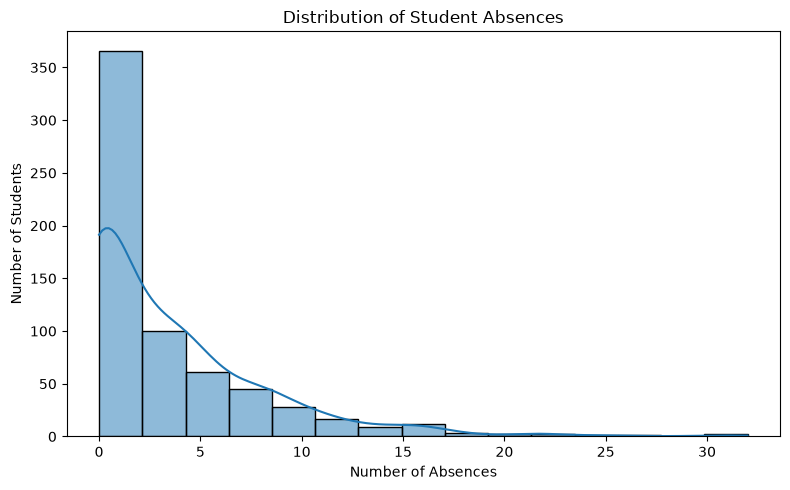

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(df["absences"], bins=15, kde=True)

plt.title("Distribution of Student Absences")
plt.xlabel("Number of Absences")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("../screenshots/absences_distribution.png", dpi=300)

plt.show()

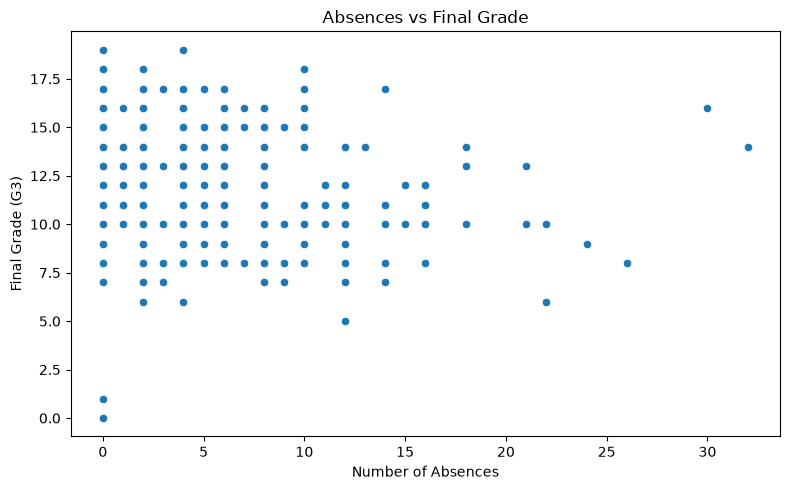

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="absences",
    y="G3"
)

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")

plt.tight_layout()
plt.savefig("../screenshots/absences_vs_g3.png", dpi=300)

plt.show()

In [23]:
correlation = df["absences"].corr(df["G3"])
print("Correlation between final grade and absences:")
print(correlation)

Correlation between final grade and absences:
-0.09137905643875621


In [24]:
from scipy.stats import pearsonr

correlation, p_value = pearsonr(df["absences"], df["G3"])

print("Pearson Correlation Test")
print("------------------------")
print("Correlation:", correlation)
print("p-value:", p_value)

Pearson Correlation Test
------------------------
Correlation: -0.09137905643875618
p-value: 0.01989562393916069


In [26]:
print("Print Previous Failures:")
print("---------------------------")
print("Mean:", df['failures'].mean())
print("Median:", df['failures'].median())
print("Max:", df['failures'].max())
print("Min:", df['failures'].min())
print("Standard Deviation:", df['failures'].std())

print("\nNumber of students in each failure category:")
print(df["failures"].value_counts().sort_index())



Print Previous Failures:
---------------------------
Mean: 0.2218798151001541
Median: 0.0
Max: 3
Min: 0
Standard Deviation: 0.5932351492649627

Number of students in each failure category:
failures
0    549
1     70
2     16
3     14
Name: count, dtype: int64


In [27]:
failures_g3 = df.groupby("failures")["G3"].agg(
    ["count", "mean", "median", "std"]
)

print("Final Grade by Previous Failure Category")
print("-----------------------------------------")
print(failures_g3)

Final Grade by Previous Failure Category
-----------------------------------------
          count       mean  median       std
failures                                    
0           549  12.510018    12.0  2.828813
1            70   8.642857    10.0  3.443270
2            16   8.812500     9.5  3.208712
3            14   8.071429     8.5  2.786348


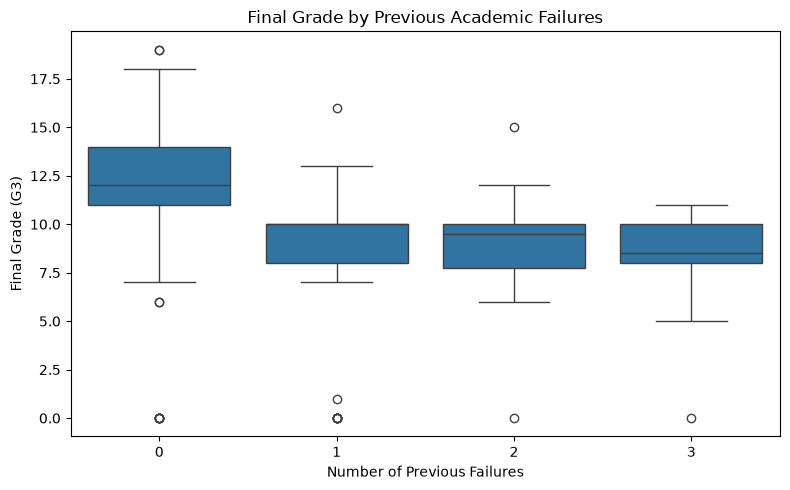

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="failures",
    y="G3"
)

plt.title("Final Grade by Previous Academic Failures")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Final Grade (G3)")

plt.tight_layout()
plt.savefig("../screenshots/failures_vs_g3.png", dpi=300)

plt.show()

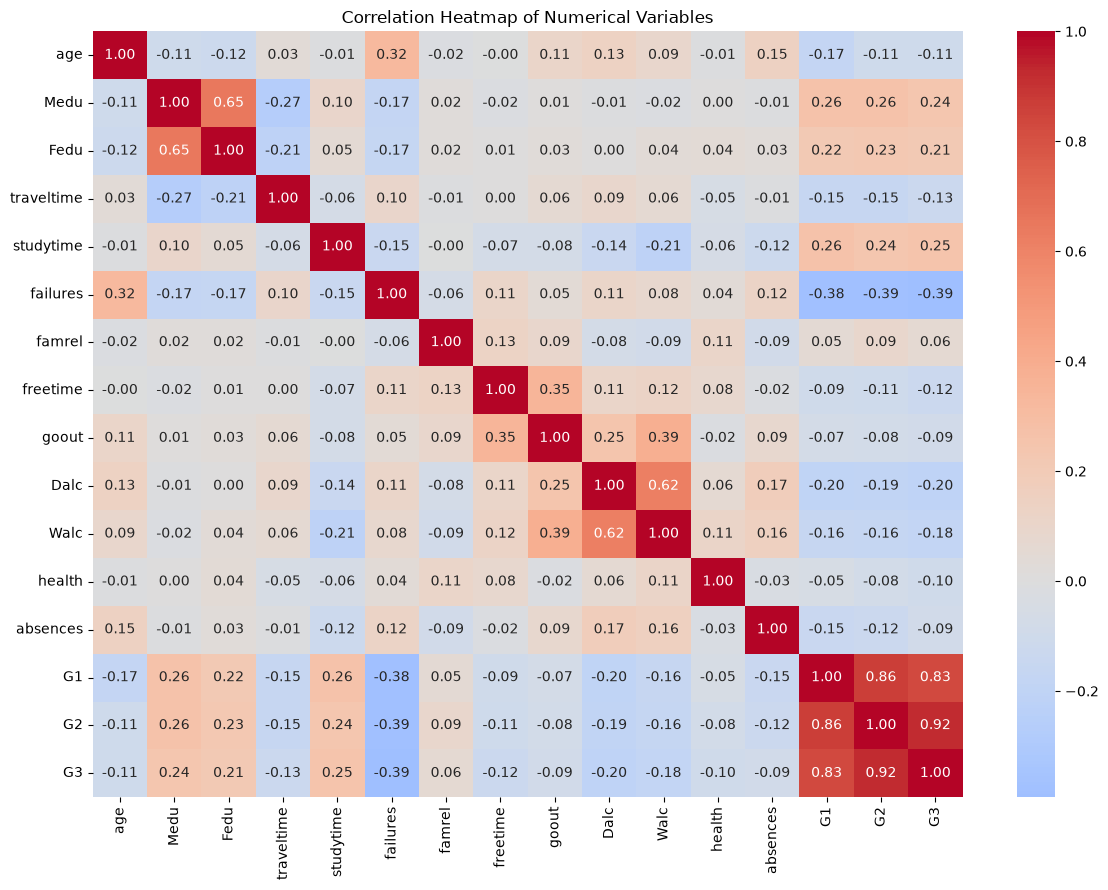

In [29]:
plt.figure(figsize=(12, 9))

correlation_matrix = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()

plt.savefig("../screenshots/correlation_heatmap.png", dpi=300)

plt.show()

In [30]:
Q1 = df["absences"].quantile(0.25)
Q3 = df["absences"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["absences"] < lower_bound) |
    (df["absences"] > upper_bound)
]

print("Absence Outlier Analysis")
print("------------------------")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

Absence Outlier Analysis
------------------------
Q1: 0.0
Q3: 6.0
IQR: 6.0
Lower Bound: -9.0
Upper Bound: 15.0
Number of Outliers: 21


# Final EDA Findings and Conclusion

## Key Findings

1. **Dataset Structure**
   - The dataset contains 649 student records and 33 variables.
   - It includes both numerical and categorical variables.
   - There are no missing values and no duplicate rows.

2. **Final Grade Distribution**
   - The final grade (G3) ranges from 0 to 19.
   - The mean final grade is approximately 11.91, while the median is 12.
   - The distribution shows variation in students' final academic performance.

3. **Study Time and Final Grade**
   - Students in higher study-time categories generally have higher average final grades.
   - A one-way ANOVA produced an F-statistic of 15.8763 and a p-value of approximately 5.71 × 10⁻¹⁰.
   - This provides statistical evidence that final-grade means differ across some study-time categories.
   - Tukey HSD analysis showed significant differences between several study-time groups.
   - These results indicate an association, not a causal relationship.

4. **Absences and Final Grade**
   - The Pearson correlation between absences and final grade is approximately -0.0914.
   - The p-value is approximately 0.0199.
   - This indicates a statistically significant but very weak negative linear association between absences and final grades.
   - The weak correlation suggests that absences alone have limited linear explanatory power for final grades.

5. **Previous Failures and Final Grade**
   - Students with no previous failures had an average final grade of approximately 12.51.
   - Students with one or more previous failures had lower average final grades in this dataset.
   - The groups with two and three previous failures are small, so their averages should be interpreted cautiously.

6. **Outliers and Anomalies**
   - The IQR method identified 21 students with more than 15 absences as potential high-end outliers.
   - These values are not necessarily data errors and may represent genuine high absenteeism.
   - The dataset also contains final-grade values of 0, which should be interpreted according to the dataset's grading context rather than automatically treated as errors.

## Overall Conclusion

The exploratory analysis identified several meaningful patterns in the student performance dataset. Study time and previous academic failures show noticeable associations with final grades, while absences have a statistically detectable but very weak negative linear relationship with final grades.

The statistical tests and visualizations support the identification of patterns and relationships within the dataset. However, the analysis is observational, so the results should not be interpreted as proof of causation.

The dataset contains no missing values or duplicate rows, but high absence values and small groups in some categories should be considered when performing further analysis or building predictive models.